# Ejercicio 1: Regresión lineal múltiple — WARECOST

## Enunciado

Un negocio de ventas por catálogo que vende suministros, software y equipo para computadoras personales tiene un almacén centralizado. La gerencia está analizando el proceso de distribución y quiere estudiar los factores que influyen en los costos de distribución del almacén. Actualmente, en cada pedido se hace un pequeño cargo adicional por manejo, independientemente de la cantidad de la compra. Los datos recopilados durante los últimos 24 meses indican los costos de distribución del almacén (en miles de dólares), las ventas (en miles de dólares) y el número de pedidos recibidos. Los datos están en `../Docs/WARECOST.xls`.

**Pregunta:** Elabore una estimación para el costo medio mensual de distribución del almacén cuando las ventas suman USD 400,000 y los pedidos son 4,500.

## Resolución paso a paso

1. **Identificar las variables:** `Cost` es el costo mensual (respuesta, miles de USD); `Sales` son las ventas mensuales (miles de USD); `Orders` es el número de pedidos. Hay 24 meses observados.
2. **Elegir el modelo:** dado que se quieren analizar simultáneamente ventas y pedidos, se ajusta una regresión lineal múltiple: $Cost = \beta_0 + \beta_1 Sales + \beta_2 Orders + \varepsilon$.
3. **Ajustar por mínimos cuadrados:** se eligen los coeficientes que minimizan la suma de residuos al cuadrado. El código muestra estimaciones, errores estándar, pruebas t y $R^2$.
4. **Estimar en el punto solicitado:** USD 400,000 son `Sales = 400` porque las ventas están expresadas en miles; el número de pedidos es `Orders = 4500`. Se calcula el costo medio ajustado y su intervalo de confianza del 95%. Este intervalo es para la media, no para predecir el costo de un mes individual.
5. **Revisar los gráficos:** dispersión, costos observados frente a ajustados y gráficos de residuos ayudan a evaluar visualmente el ajuste. No prueban por sí solos los supuestos de linealidad, independencia, varianza constante y normalidad.

El coeficiente de `Orders` mide el cambio estimado del costo por pedido adicional, manteniendo las ventas constantes. El análisis muestra asociaciones, no demuestra causalidad.

Archivo: C:\Users\Gasti\Desktop\MPG\Docs\WARECOST.xls
Observaciones: 24 meses


,Cost,Sales,Orders
0,52.95,386,4015
1,71.66,446,3806
2,85.58,512,5309
3,63.69,401,4262
4,72.81,457,4296


,Coeficiente,Error estándar,t,p-valor
Intercepto,-2.728247,6.157880,-0.443050,0.662260
Sales (miles de USD),0.047114,0.020328,2.317693,0.030644
Orders (pedidos),0.011947,0.002249,5.313123,0.000029


R² = 0.8759 | R² ajustado = 0.8641 | Error estándar residual = 4.7662 miles de USD
Ecuación estimada: Cost_hat = -2.7282 + 0.04711·Sales + 0.01195·Orders
Interpretación de Orders: cada pedido adicional se asocia con USD 11.95 en el costo, manteniendo Sales constante.

RESULTADO SOLICITADO
Costo medio estimado: 69.878 miles de USD = USD 69,878.47
IC del 95% para el costo medio: [66.420, 73.337] miles de USD
En dólares: [USD 66,419.93, USD 73,337.01]


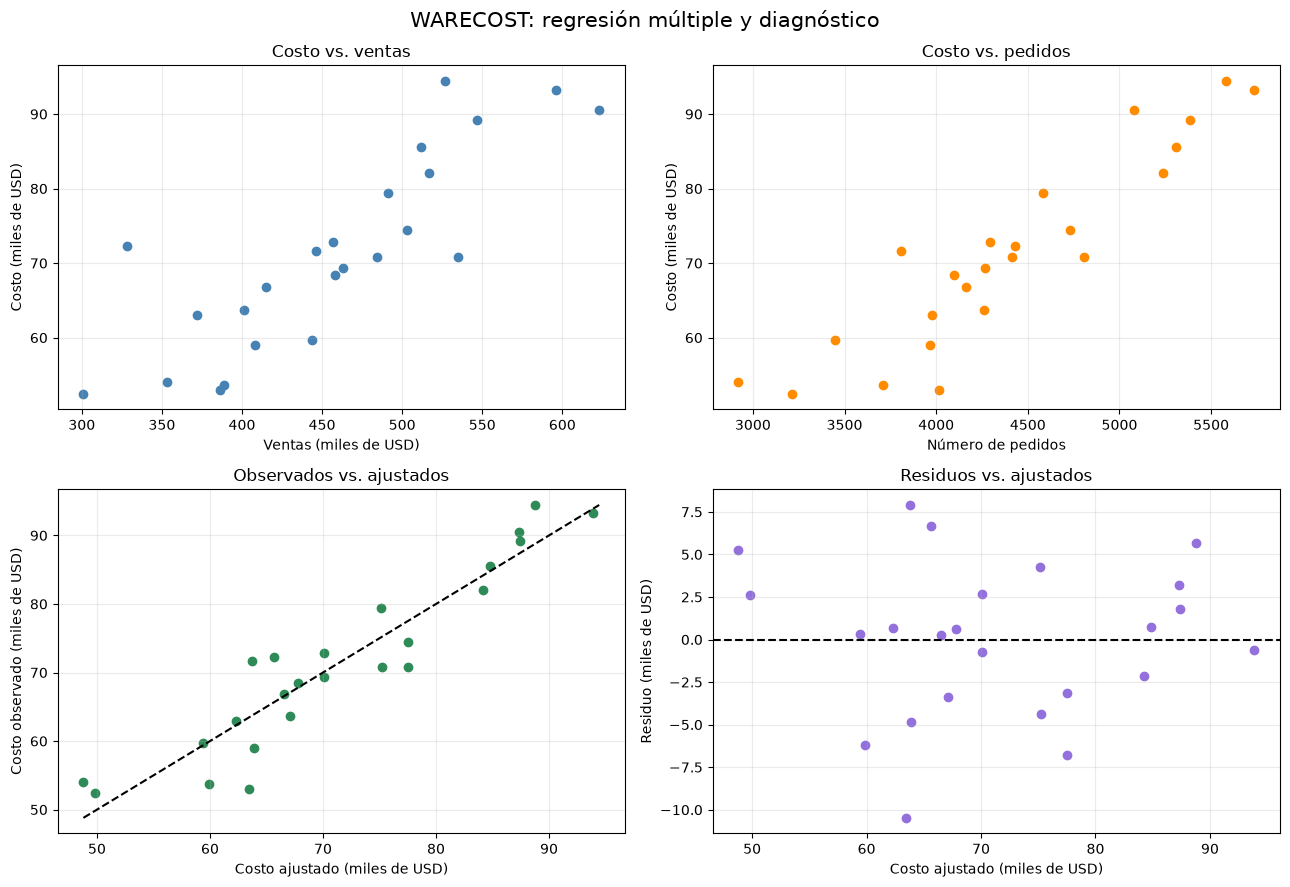

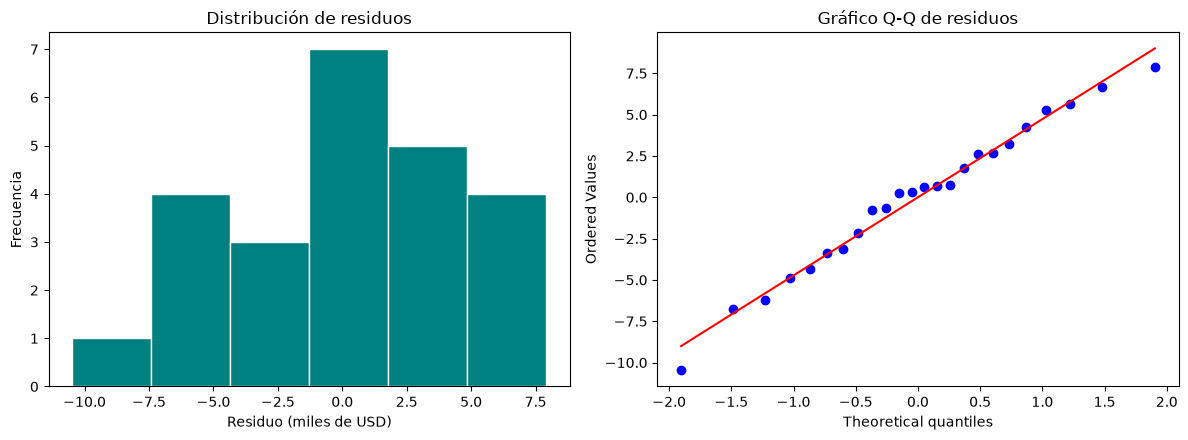

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# Busca el libro tanto si Jupyter inició en la raíz como en Regresion_lineal.
rutas = [Path("Docs/WARECOST.xls"), Path("../Docs/WARECOST.xls")]
archivo = next((ruta for ruta in rutas if ruta.is_file()), None)
if archivo is None:
    raise FileNotFoundError(
        "No se encontró WARECOST.xls. Comprueba que el archivo esté en la carpeta Docs del proyecto."
    )

datos = pd.read_excel(archivo)
columnas = ["Cost", "Sales", "Orders"]
faltantes = set(columnas).difference(datos.columns)
if faltantes:
    raise ValueError(f"Faltan columnas en WARECOST.xls: {sorted(faltantes)}")
if len(datos) != 24 or datos[columnas].isna().any().any():
    raise ValueError("Se esperaban 24 observaciones completas en Cost, Sales y Orders.")

print(f"Archivo: {archivo.resolve()}")
print(f"Observaciones: {len(datos)} meses")
display(datos.head())

# Modelo: Cost = beta_0 + beta_1*Sales + beta_2*Orders + error.
y = datos["Cost"].to_numpy(dtype=float)
X = np.column_stack(
    [np.ones(len(datos)), datos["Sales"].to_numpy(dtype=float), datos["Orders"].to_numpy(dtype=float)]
)
n, k = X.shape
gl_error = n - k
beta, _, _, _ = np.linalg.lstsq(X, y, rcond=None)
ajustados = X @ beta
residuos = y - ajustados
sse = float(residuos @ residuos)
mse = sse / gl_error
cov_beta = mse * np.linalg.inv(X.T @ X)
ee_beta = np.sqrt(np.diag(cov_beta))
t_beta = beta / ee_beta
p_beta = 2 * stats.t.sf(np.abs(t_beta), gl_error)
r2 = 1 - sse / np.sum((y - y.mean()) ** 2)
r2_ajustado = 1 - (1 - r2) * (n - 1) / gl_error

tabla = pd.DataFrame(
    {"Coeficiente": beta, "Error estándar": ee_beta, "t": t_beta, "p-valor": p_beta},
    index=["Intercepto", "Sales (miles de USD)", "Orders (pedidos)"],
)
display(tabla)
print(f"R² = {r2:.4f} | R² ajustado = {r2_ajustado:.4f} | Error estándar residual = {np.sqrt(mse):.4f} miles de USD")
print(f"Ecuación estimada: Cost_hat = {beta[0]:.4f} + {beta[1]:.5f}·Sales + {beta[2]:.5f}·Orders")
print(f"Interpretación de Orders: cada pedido adicional se asocia con USD {beta[2] * 1000:.2f} en el costo, manteniendo Sales constante.")

# Estimación e IC del 95% para el costo medio en Sales=400 y Orders=4500.
x0 = np.array([1.0, 400.0, 4500.0])
media = float(x0 @ beta)
ee_media = np.sqrt(mse * float(x0 @ np.linalg.inv(X.T @ X) @ x0))
t_critico = stats.t.ppf(0.975, gl_error)
li, ls = media - t_critico * ee_media, media + t_critico * ee_media
print("\nRESULTADO SOLICITADO")
print(f"Costo medio estimado: {media:.3f} miles de USD = USD {media * 1000:,.2f}")
print(f"IC del 95% para el costo medio: [{li:.3f}, {ls:.3f}] miles de USD")
print(f"En dólares: [USD {li * 1000:,.2f}, USD {ls * 1000:,.2f}]")

# Gráficos de relaciones y diagnóstico.
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
ax[0, 0].scatter(datos["Sales"], y, color="steelblue")
ax[0, 0].set(title="Costo vs. ventas", xlabel="Ventas (miles de USD)", ylabel="Costo (miles de USD)")
ax[0, 1].scatter(datos["Orders"], y, color="darkorange")
ax[0, 1].set(title="Costo vs. pedidos", xlabel="Número de pedidos", ylabel="Costo (miles de USD)")
ax[1, 0].scatter(ajustados, y, color="seagreen")
extremos = [min(y.min(), ajustados.min()), max(y.max(), ajustados.max())]
ax[1, 0].plot(extremos, extremos, "k--")
ax[1, 0].set(title="Observados vs. ajustados", xlabel="Costo ajustado (miles de USD)", ylabel="Costo observado (miles de USD)")
ax[1, 1].scatter(ajustados, residuos, color="mediumpurple")
ax[1, 1].axhline(0, color="black", linestyle="--")
ax[1, 1].set(title="Residuos vs. ajustados", xlabel="Costo ajustado (miles de USD)", ylabel="Residuo (miles de USD)")
for eje in ax.flat:
    eje.grid(alpha=0.25)
fig.suptitle("WARECOST: regresión múltiple y diagnóstico", fontsize=15)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].hist(residuos, bins="auto", edgecolor="white", color="teal")
ax[0].set(title="Distribución de residuos", xlabel="Residuo (miles de USD)", ylabel="Frecuencia")
stats.probplot(residuos, dist="norm", plot=ax[1])
ax[1].set(title="Gráfico Q-Q de residuos")
fig.tight_layout()
plt.show()

## Conclusión

Con el archivo WARECOST, el modelo estima un costo medio mensual de aproximadamente **USD 69,878.47** cuando las ventas son USD 400,000 y se reciben 4,500 pedidos. El intervalo de confianza del 95% para el costo medio es aproximadamente **USD 66,419.93 a USD 73,337.01**. El intervalo corresponde a la media bajo esas condiciones, no al costo de un mes individual.